# Khám phá tập dữ liệu D3S

Task T0202 đánh giá inventory cho Hệ thống Phát hiện Buồn ngủ của Tài xế. Notebook này đọc file `data/metadata/d3s_inventory.csv`, tóm tắt siêu dữ liệu (metadata) ở cấp độ video, và ghi chép lại hướng dẫn chia tách dữ liệu sao cho giữ nguyên được ranh giới của đối tượng/video.

In [1]:
from collections import Counter
import csv
from pathlib import Path
import matplotlib.pyplot as plt

repo_root = Path.cwd().resolve()
inventory_path = repo_root / 'data' / 'metadata' / 'd3s_inventory.csv'
with inventory_path.open(newline='', encoding='utf-8') as csv_file:
    records = list(csv.DictReader(csv_file))

print(f'Đã tải {len(records)} bản ghi video từ {inventory_path}')

Đã tải 1 bản ghi video từ data/metadata/d3s_inventory.csv


In [2]:
for record in records:
    print(
        record['video_id'],
        record['relative_path'],
        record['subject_id'],
        record['label'],
        record['resolution'],
        record['fps'],
        record['total_frames'],
        record['duration_sec'],
    )

d3s_0001 d3s/d3s_video_dataset.mp4 UNKNOWN UNKNOWN 1920x1080 23.976024 4673 194.903042


## Nguồn gốc của Siêu dữ liệu (Metadata Provenance)

Các nhãn về đối tượng và phân lớp chỉ được phân tích cú pháp từ các thành phần trong đường dẫn hoặc tên file, ví dụ như `subject_02/yawning/sample.mp4`. Cấu trúc D3S nội bộ hiện tại là một file MP4 nguyên khối duy nhất có tên là `d3s_video_dataset.mp4`, vì vậy các trường đối tượng và nhãn của nó sẽ duy trì trạng thái `UNKNOWN` (Không xác định) cho đến khi nhóm dự án nhập vào một cấu trúc phát hành khung hình/video bài bản hoặc bổ sung thêm các chú thích phân đoạn đã được kiểm chứng.

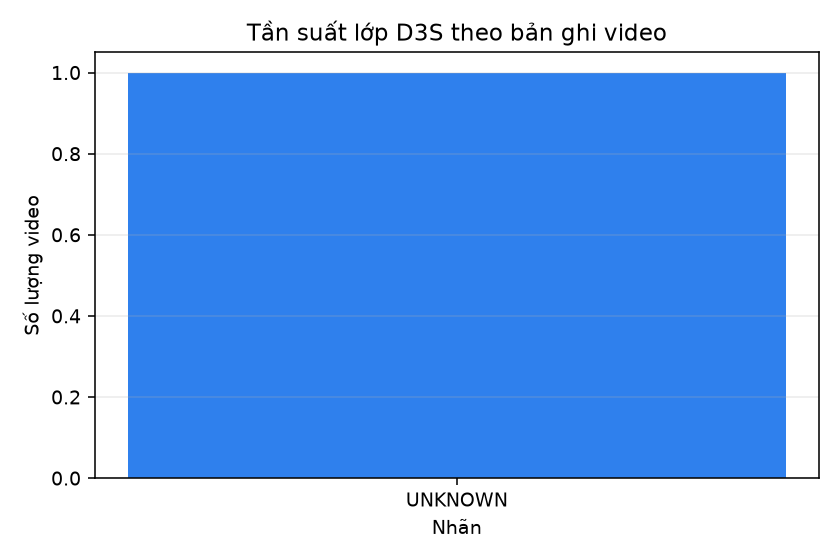

In [3]:
label_counts = Counter(
    record['label'] for record in records
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(label_counts.keys(), label_counts.values(), color='#2f80ed')
ax.set_title('Tần suất lớp D3S theo bản ghi video')
ax.set_xlabel('Nhãn')
ax.set_ylabel('Số lượng video')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

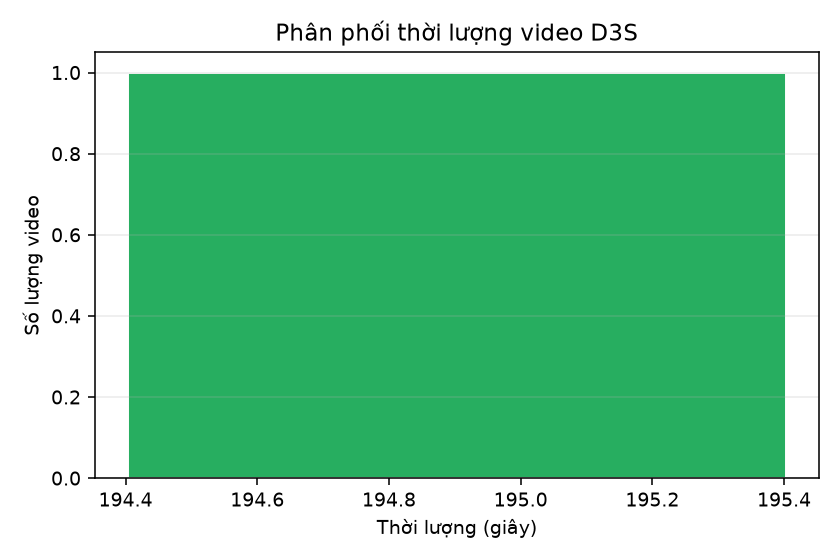

In [4]:
durations = [float(record['duration_sec']) for record in records]
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(durations, bins=max(1, min(8, len(durations))), color='#27ae60', edgecolor='white')
ax.set_title('Phân phối thời lượng video D3S')
ax.set_xlabel('Thời lượng (giây)')
ax.set_ylabel('Số lượng video')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

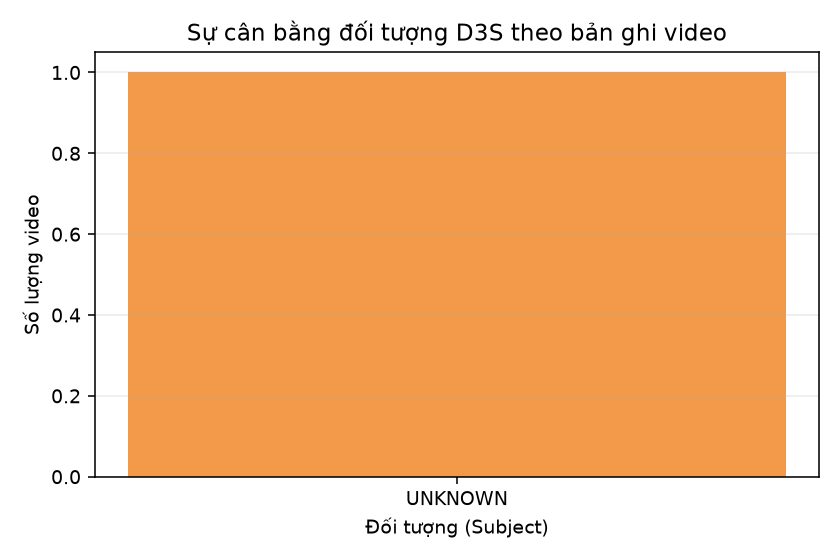

In [5]:
subject_counts = Counter(
    record['subject_id'] for record in records
)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(subject_counts.keys(), subject_counts.values(), color='#f2994a')
ax.set_title('Sự cân bằng đối tượng D3S theo bản ghi video')
ax.set_xlabel('Đối tượng (Subject)')
ax.set_ylabel('Số lượng video')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()

## Hướng dẫn Chia tách Cấp độ Đối tượng

- Chia tách theo đối tượng khi có sẵn ID đối tượng: ví dụ, huấn luyện trên hai đối tượng và giữ lại đối tượng thứ ba để kiểm tra (validation) hoặc thử nghiệm (testing).
- Nếu một đối tượng không thể tách rời, hãy chia tách theo toàn bộ video nguồn hoặc phiên làm việc liền kề đã được xác minh, tuyệt đối không chia tách bằng cách xáo trộn ngẫu nhiên các khung hình.
- Giữ các khung hình lân cận từ cùng một tài xế/phiên làm việc nằm trong cùng một phân vùng để các tín hiệu chuỗi thời gian không bị rò rỉ sang tập dữ liệu đánh giá.
- Báo cáo các bản ghi `UNKNOWN` và không hợp lệ một cách riêng biệt trong quá trình đánh giá thay vì âm thầm loại bỏ chúng.

In [6]:
unparsed = [
    record for record in records
    if record['subject_id'] == 'UNKNOWN'
    or record['label'] == 'UNKNOWN'
]
print(f'Các hàng cần nhãn xác minh: {len(unparsed)}')
for record in unparsed:
    print(record['relative_path'])

Các hàng cần nhãn xác minh: 1
d3s/d3s_video_dataset.mp4
